# Modelado: baselines, cinco modelos y búsqueda de hiperparámetros con Optuna

**Objetivo.** Pronosticar al cierre del día **D** el consumo de frío de **D+1** con los modelos que pide la consigna (Ridge, Lasso, Random Forest, XGBoost y LightGBM), compararlos contra los dos baselines obligatorios y elegir el mejor por MAE en Validation.

**Entrada.** Las predictoras del preprocesamiento y las candidatas de la selección: derivadas del frío, calendario, ciclo anual, binning, interacciones y maquinaria funcionando. Las candidatas se reconstruyen con `src/preprocessing_pipeline.py` y se verifica que el historial y la configuración sean los mismos que usó la selección.

**Cómo se buscan los hiperparámetros.** Para cada modelo, Optuna (muestreador TPE, semilla 42) prueba combinaciones de hiperparámetros, **del conjunto de variables** (uno de los subconjuntos que eligió la selección, o todas las que pasaron el filtro de redundancia) **y de qué aprende el modelo**: el nivel del frío de mañana o su cambio respecto de hoy (sección 3.1). Cada combinación se puntúa con el MAE medio de una validación temporal interna en Train (`TimeSeriesSplit`, 5 bloques, un día de hueco).

**Reglas contra la fuga de información:**

1. Optuna **nunca ve Validation ni Test**: su objetivo es el error interno en Train.
2. **Validation se usa una vez**, para comparar la mejor configuración de cada modelo y elegir el ganador.
3. **Test se lee solo en la sección 9**, una sola vez y después de congelar la elección con el criterio fijado de antemano (menor MAE en Validation). Cambiar algo después de mirar Test invalida esa medición.
4. El escalado de Ridge y Lasso vive dentro del `Pipeline` y se ajusta en cada bloque.

Toda la lógica vive en `src/train_model.py`. `python -m src.train_model` repite los mismos pasos desde la terminal. Cada trial, cada candidato y cada baseline se agregan a `results/experiment_logs.csv`.

| Sección | Contenido |
|---|---|
| 1 | Datos y conjuntos de variables |
| 2 | Baselines |
| 3 | Espacio de búsqueda |
| 4 | Optimización con Optuna |
| 5 | Comparación en Validation, por conjunto (5.1) y por objetivo (5.2) |
| 6 | Diagnóstico del ganador |
| 7 | Importancia de variables |
| 8 | Registro de experimentos y archivos |
| 9 | Evaluación final en Test, registro del modelo y verificación de `predict.py` |
| 10 | Conclusiones |

In [1]:
import json
import sys
import time
import warnings
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
from IPython.display import display
from sklearn.exceptions import ConvergenceWarning
from sklearn.inspection import permutation_importance

raiz = Path.cwd()
if raiz.name == "notebooks":
    raiz = raiz.parent
if str(raiz) not in sys.path:
    sys.path.insert(0, str(raiz))

from src import auxiliar_functions as af
from src import train_model as tm
from src import preprocessing_pipeline as pp

warnings.filterwarnings("ignore", category=ConvergenceWarning)
optuna.logging.set_verbosity(optuna.logging.WARNING)
pd.set_option("display.max_colwidth", 80)
pd.set_option("display.width", 200)

# Un color fijo por modelo (paleta categórica del proyecto, en orden).
COLORES = {"Ridge": "#2a78d6", "Lasso": "#eb6834", "Random Forest": "#1baf7a",
           "XGBoost": "#eda100", "LightGBM": "#e87ba4"}
plt.rcParams.update({
    "figure.figsize": (12, 4), "axes.grid": True, "grid.alpha": 0.25,
    "axes.spines.top": False, "axes.spines.right": False, "lines.linewidth": 1.4,
    "axes.titleweight": "bold", "axes.titlesize": 11,
})

def corto(nombre, largo=40):
    base = nombre.rsplit("_", 1)[0] if "_Consolidado" in nombre or "_Totalizadores" in nombre else nombre
    return base if len(base) <= largo else base[:largo - 1] + "…"

# Test se evalúa una sola vez, con la elección ya congelada por el criterio de la sección 5.
# Con False, la notebook se detiene antes de Test (para seguir probando sin mirarlo).
EVALUAR_TEST = True

cfg = tm.ConfigModelado()
corrida = datetime.now(timezone.utc).isoformat()  # agrupa las filas de esta ejecución en el log
display(pd.Series({k: v for k, v in vars(cfg).items()}, name="valor").to_frame())

,valor
modelos,"(Ridge, Lasso, Random Forest, XGBoost, LightGBM)"
n_trials,"((Ridge, 40), (Lasso, 40), (Random Forest, 60), (XGBoost, 80), (LightGBM, 100))"
conjuntos,"(mutual_information, forward, consenso_2_metodos, ridge, lasso, todas)"
objetivos,"(nivel,)"
n_splits,5
gap,1
n_jobs_bloques,-1
registrar_log,True


## 1. Datos y conjuntos de variables

`cargar_datos` verifica el SHA-256 del historial preprocesado y repite en memoria la selección de `seleccion.ipynb` (alrededor de un minuto) para reconstruir las candidatas y sus subconjuntos, así que los subconjuntos siempre corresponden a las mismas columnas.

Optuna elige entre seis conjuntos: los de Mutual Information, forward, Ridge y Lasso, el consenso de al menos dos métodos y todas las candidatas. Van de 25 a 383 columnas y mezclan las familias en proporciones distintas. Así cada modelo puede quedarse con el conjunto que le conviene: un modelo lineal puede necesitar pocas variables y un modelo de árboles puede aprovechar más.

In [2]:
d = tm.cargar_datos()
X_tr, y_tr, _ = d["train"]
X_val, y_val, _ = d["validation"]
subconjuntos = {c: d["subconjuntos"][c] for c in cfg.conjuntos}

print(f"X_train: {X_tr.shape} ({X_tr.index.min().date()} a {X_tr.index.max().date()})")
print(f"X_val:   {X_val.shape} ({X_val.index.min().date()} a {X_val.index.max().date()})")

familias = pd.DataFrame({nombre: pd.Series([pp.familia_de(c) for c in cols]).value_counts()
                         for nombre, cols in subconjuntos.items()}).fillna(0).astype(int)
familias.loc["total"] = familias.sum()
print("Columnas de cada conjunto, por familia:")
display(familias)

X_train: (786, 360) (2020-07-15 a 2022-10-26)
X_val:   (171, 360) (2022-10-27 a 2023-04-29)
Columnas de cada conjunto, por familia:


,mutual_information,forward,consenso_2_metodos,ridge,lasso,todas
binning,0,0,2,2,4,17
calendario,0,2,3,5,2,6
ciclo anual,1,1,1,2,1,4
derivada del frío,7,6,8,24,3,35
eficiencia vs meta,0,1,1,2,0,4
interacción,0,1,1,5,1,14
preprocesamiento,0,11,24,77,27,269
ratio entre áreas,0,1,2,3,3,11
total,8,23,42,120,41,360


## 2. Baselines

Los dos baselines obligatorios se calculan sobre **las mismas filas de Validation** que los modelos:

* **Persistencia:** mañana se consume lo mismo que hoy, ŷ(D+1) = frío(D).
* **Media móvil de 7 días:** promedio de los últimos 7 cierres hasta D. Es la misma media que usa la selección: si falta un día calendario, la ventana toma el cierre anterior, así nunca queda vacía.

Cualquier modelo tiene que mejorar al mejor de los dos para justificar su complejidad.

In [3]:
tabla_baselines = tm.baselines(X_val, y_val)
for _, fila in tabla_baselines.iterrows():
    tm.registrar(tm.RUTA_LOG, "baseline", fila["modelo"], "v2", {}, "validation", 0, X_val.index,
                  {k: fila[k] for k in ("mae", "rmse", "r2")}, corrida)
mejor_baseline = tabla_baselines["mae"].min()
display(tabla_baselines.round(1))

,modelo,mae,rmse,r2
0,Persistencia,2727.1,3362.1,0.2
1,Media móvil de 7 días,2398.3,3159.8,0.3


## 3. Espacio de búsqueda

| Modelo | Qué aprende | Por qué esos rangos |
|---|---|---|
| Ridge | Combinación lineal con penalización L2 | `alpha` en escala logarítmica de 0,01 a 10.000: de casi sin penalización a coeficientes muy contraídos. Las variables del frío están muy correlacionadas y L2 reparte el peso entre ellas. |
| Lasso | Combinación lineal con penalización L1, que lleva coeficientes a cero | `alpha` de 0,1 a 3.000: con el MAE en kW y las variables estandarizadas, valores mayores dejan casi todos los coeficientes en cero. |
| Random Forest | Promedio de árboles profundos sobre muestras distintas | Con 786 días de Train, la profundidad y el tamaño mínimo de hoja controlan el sobreajuste. `max_features` decorrelaciona los árboles. Se usa el error cuadrático como criterio: el absoluto es mucho más lento en scikit-learn. |
| XGBoost | Suma de árboles chicos, cada uno corrige a los anteriores | La tasa de aprendizaje y la cantidad de árboles se compensan. `subsample` y `colsample_bytree` agregan azar, `min_child_weight` y `reg_lambda` regularizan. La pérdida puede ser cuadrática o absoluta (la absoluta optimiza directamente el MAE). |
| LightGBM | Igual que XGBoost, con árboles que crecen hoja por hoja | `num_leaves` reemplaza a la profundidad; `min_child_samples` evita hojas con pocos días. Mismas opciones de pérdida. |

Todos los modelos buscan además el **conjunto de variables**. La cantidad de trials crece con la cantidad de hiperparámetros. Ridge, Random Forest, XGBoost y LightGBM se crean con `crear_modelo` de `src/train_model.py` (los mismos estimadores de la versión anterior); Lasso se agrega en `src/train_model.py`.

In [4]:
display(pd.DataFrame({"hiperparámetros": tm.ESPACIO_BUSQUEDA,
                      "trials": {m: cfg.trials(m) for m in cfg.modelos}}))

,hiperparámetros,trials
Ridge,"alpha ∈ [0,01; 10.000] (log)",40
Lasso,"alpha ∈ [0,1; 3.000] (log)",40
Random Forest,n_estimators 100–600; max_depth 3–20; min_samples_leaf 1–30; max_features ∈ ...,60
XGBoost,"n_estimators 100–1.000; learning_rate 0,01–0,3 (log); max_depth 2–8; min_chi...",80
LightGBM,"n_estimators 100–1.000; learning_rate 0,01–0,3 (log); num_leaves 4–64 (log);...",100


### 3.1 Qué aprende el modelo (decisión abierta)

Además de los hiperparámetros y del conjunto, Optuna elige **qué aprende** el modelo. Las opciones están en `OBJETIVOS` (`src/train_model.py`):

| Opción | El modelo aprende | Al predecir |
|---|---|---|
| `nivel` | `y`, el frío de D+1 (como en la versión anterior) | Devuelve lo que predice |
| `cambio` | `y − frío de D` | Suma el frío de D |
| `cambio_media7` | `y − media de los últimos 7 cierres` | Suma esa media |
| `cociente_media7` | `y / media de los últimos 7 cierres` | Multiplica por esa media |

**Por qué se prueba.** El error principal del modelo anterior era de nivel: en enero de 2023 subestimó 2.345 kW en promedio, y la EDA muestra que los picos de verano bajan año a año. Un árbol no puede predecir valores fuera de los que vio en Train. Un cambio diario, en cambio, sí suele estar dentro de ese rango.

**Qué no cambia.** La base es una predictora conocida al cierre de D, así que no se usa información futura. Las métricas se miden siempre sobre `y` en kW, porque el modelo devuelve el nivel aunque aprenda el cambio. Los baselines son los mismos.

**Cómo fijarlo.** `ConfigModelado.objetivos` lista las opciones. **Por defecto es `("nivel",)`**, que reproduce la versión registrada `v2.0.0`; con una sola opción la búsqueda no agrega ningún parámetro. Para usar otra, alcanza con cambiar esa línea, por ejemplo a `("cambio_media7",)`. Con varias, Optuna elige entre ellas con la validación interna en Train. La sección 5.2 muestra la comparación de las cuatro opciones, que es la evidencia para discutir esta decisión.

## 4. Optimización con Optuna

Cada trial ajusta el modelo en los 5 bloques de la validación interna (en paralelo) y devuelve el MAE medio. Los trials corren en serie con semilla fija, así que dos ejecuciones dan los mismos resultados. Esta celda tarda unos minutos.

In [5]:
estudios, tiempos = {}, {}
for modelo in cfg.modelos:
    inicio = time.perf_counter()
    estudios[modelo] = tm.optimizar(modelo, X_tr, y_tr, subconjuntos, cfg, corrida)
    tiempos[modelo] = time.perf_counter() - inicio
    print(f"{modelo:<14} {cfg.trials(modelo):>3} trials en {tiempos[modelo]:5.0f} s | "
          f"mejor MAE interno {estudios[modelo].best_value:,.1f} kW")

trials = tm.tabla_trials(estudios)
resumen_optuna = pd.DataFrame([{
    "modelo": m,
    "mejor MAE interno": e.best_value,
    "desvío entre bloques": e.best_trial.user_attrs["mae_desvio"],
    "conjunto": tm.mejor_configuracion(e)[0],
    "columnas": e.best_trial.user_attrs["n_columnas"],
    "hiperparámetros": tm.mejor_configuracion(e)[1],
} for m, e in estudios.items()]).set_index("modelo")
display(resumen_optuna.round(1))

Ridge           40 trials en     7 s | mejor MAE interno 2,736.3 kW


Lasso           40 trials en     6 s | mejor MAE interno 2,839.2 kW


Random Forest   60 trials en    41 s | mejor MAE interno 3,406.2 kW


XGBoost         80 trials en    53 s | mejor MAE interno 3,398.4 kW


LightGBM       100 trials en    14 s | mejor MAE interno 3,349.5 kW


,mejor MAE interno,desvío entre bloques,conjunto,columnas,hiperparámetros
modelo,,,,,
Ridge,2736.3,345.0,forward,23,"{'alpha': 73.71931195045953, 'objetivo_y': 'nivel'}"
Lasso,2839.2,320.2,forward,23,"{'alpha': 31.107092841598856, 'objetivo_y': 'nivel'}"
Random Forest,3406.2,617.8,forward,23,"{'n_estimators': 200, 'max_depth': 11, 'min_samples_leaf': 3, 'max_features'..."
XGBoost,3398.4,754.3,lasso,41,"{'n_estimators': 300, 'learning_rate': 0.03461617453314415, 'max_depth': 2, ..."
LightGBM,3349.5,791.3,forward,23,"{'n_estimators': 500, 'learning_rate': 0.04457467998751702, 'num_leaves': 4,..."


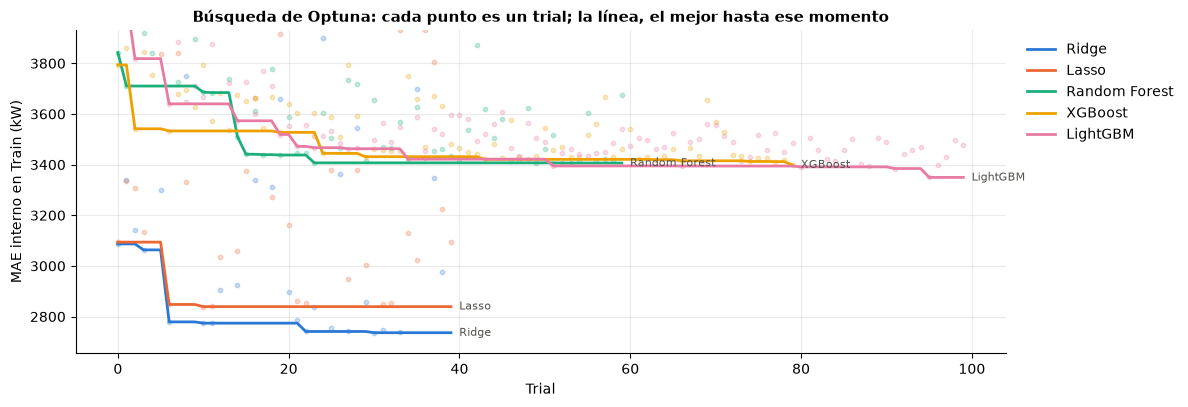

El eje vertical se corta en el percentil 90 de los trials (3,931 kW) para que se vean las diferencias.


In [6]:
fig, ax = plt.subplots(figsize=(12, 4.2))
for modelo, estudio in estudios.items():
    valores = pd.Series([t.value for t in estudio.trials])
    mejor = valores.cummin()
    ax.scatter(valores.index, valores, s=10, color=COLORES[modelo], alpha=0.25)
    ax.plot(mejor.index, mejor, color=COLORES[modelo], lw=2, label=modelo)
    ax.annotate(modelo, (mejor.index[-1], mejor.iloc[-1]), xytext=(6, 0), textcoords="offset points",
                fontsize=8, color="#52514e", va="center")
limite = trials["mae_interno"].quantile(0.9)
ax.set_ylim(trials["mae_interno"].min() * 0.97, limite)
ax.set_xlabel("Trial")
ax.set_ylabel("MAE interno en Train (kW)")
ax.set_title("Búsqueda de Optuna: cada punto es un trial; la línea, el mejor hasta ese momento")
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1))
plt.show()
print(f"El eje vertical se corta en el percentil 90 de los trials ({limite:,.0f} kW) para que se vean las diferencias.")

In [7]:
# ¿Qué conjunto de variables le conviene a cada modelo? Mejor MAE interno con cada uno
# y cuántos trials lo probaron (TPE prueba más los conjuntos que vienen funcionando).
por_conjunto = trials.pivot_table(index="conjunto", columns="modelo", values="mae_interno", aggfunc="min")
conteo = trials.pivot_table(index="conjunto", columns="modelo", values="trial", aggfunc="count").fillna(0).astype(int)
print("Mejor MAE interno (kW) por conjunto y modelo:")
display(por_conjunto[list(cfg.modelos)].round(0))
print("Trials por conjunto y modelo:")
display(conteo[list(cfg.modelos)])

Mejor MAE interno (kW) por conjunto y modelo:


modelo,Ridge,Lasso,Random Forest,XGBoost,LightGBM
conjunto,,,,,
consenso_2_metodos,2897.0,3160.0,3578.0,3681.0,3884.0
forward,2736.0,2839.0,3406.0,3696.0,3350.0
lasso,2856.0,3003.0,3684.0,3398.0,3640.0
mutual_information,3301.0,3274.0,3739.0,3604.0,NaN
ridge,3142.0,3309.0,3674.0,3574.0,3770.0
todas,3700.0,3374.0,3777.0,3843.0,4018.0


Trials por conjunto y modelo:


modelo,Ridge,Lasso,Random Forest,XGBoost,LightGBM
conjunto,,,,,
consenso_2_metodos,4,5,4,2,2
forward,16,15,41,2,87
lasso,6,5,7,69,6
mutual_information,4,5,3,2,0
ridge,3,5,2,2,1
todas,7,5,3,3,4


**Lectura:**

* **Los lineales logran el menor error interno:** Ridge 2.736 kW y Lasso 2.839 kW; los de árboles, entre 3.350 (LightGBM) y 3.406 kW (Random Forest).
* **Casi todos eligen el conjunto de forward** (23 columnas): TPE lo probó en 87 de los 100 trials de LightGBM y en 41 de los 60 de Random Forest. XGBoost es la excepción y prefiere el de Lasso (41 columnas).
* **Todas las candidatas es el peor conjunto para los cinco modelos** (3.374 a 4.018 kW): con 360 columnas y 786 días, el ruido pesa más que la información.
* **Hiperparámetros elegidos:** Ridge con alpha ≈ 74 y Lasso con ≈ 31; Random Forest con 200 árboles de profundidad 11, hojas de al menos 3 días y 60 % de las variables en cada corte; XGBoost con 300 árboles de profundidad 2 y LightGBM con 500 árboles de 4 hojas, los dos con **pérdida absoluta**, que optimiza directamente el MAE.
* **La búsqueda converge** en los primeros 20 a 30 trials. Las diferencias entre los mejores (103 kW entre Ridge y Lasso) son chicas frente al desvío entre bloques de la validación interna (320 a 791 kW).

## 5. Comparación en Validation

La mejor configuración de cada modelo se ajusta con **todo Train** y se evalúa una sola vez en Validation. Se reportan MAE (criterio de elección), RMSE (pesa más los errores grandes), R² y el **sesgo** (predicción − real promedio: positivo si el modelo sobreestima). Gana el menor MAE; ante un empate, el de menos columnas.

In [8]:
comparacion, ajustados, predicciones = tm.evaluar_en_validation(
    estudios, subconjuntos, X_tr, y_tr, X_val, y_val, corrida, cfg)
tabla_val = pd.concat([comparacion.drop(columns="hiperparametros"), tabla_baselines], ignore_index=True)
tabla_val["vs mejor baseline"] = (1 - tabla_val["mae"] / mejor_baseline).map("{:+.1%}".format)
display(tabla_val.round(1))

ganador = comparacion.iloc[0]
print(f"Ganador: {ganador['modelo']} con el conjunto {ganador['conjunto']} ({ganador['n_columnas']} columnas) | "
      f"MAE {ganador['mae']:,.1f} kW | mejora sobre el mejor baseline: {1 - ganador['mae'] / mejor_baseline:.1%}")

,modelo,conjunto,n_columnas,mae_interno,mae,rmse,r2,sesgo,vs mejor baseline
0,Random Forest,forward,23.0,3406.2,2297.6,2859.6,0.4,38.7,+4.2%
1,XGBoost,lasso,41.0,3398.4,2318.6,2931.9,0.4,776.7,+3.3%
2,Ridge,forward,23.0,2736.3,2320.7,2951.6,0.4,246.6,+3.2%
3,Lasso,forward,23.0,2839.2,2397.2,3048.1,0.4,364.9,+0.0%
4,LightGBM,forward,23.0,3349.5,2455.3,2999.4,0.4,721.2,-2.4%
5,Persistencia,NaN,NaN,NaN,2727.1,3362.1,0.2,NaN,-13.7%
6,Media móvil de 7 días,NaN,NaN,NaN,2398.3,3159.8,0.3,NaN,+0.0%


Ganador: Random Forest con el conjunto forward (23 columnas) | MAE 2,297.6 kW | mejora sobre el mejor baseline: 4.2%


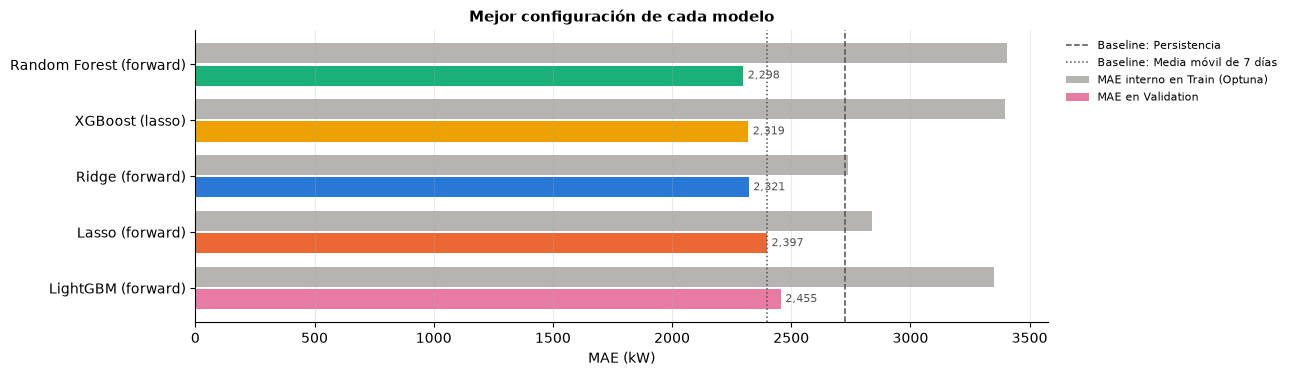

In [9]:
fig, ax = plt.subplots(figsize=(11, 3.8))
orden = comparacion.sort_values("mae", ascending=False)
pos = np.arange(len(orden))
ax.barh(pos + 0.2, orden["mae_interno"], height=0.36, color="#b5b4b0", label="MAE interno en Train (Optuna)")
ax.barh(pos - 0.2, orden["mae"], height=0.36, color=[COLORES[m] for m in orden["modelo"]], label="MAE en Validation")
for i, (_, fila) in enumerate(orden.iterrows()):
    ax.text(fila["mae"] + 20, i - 0.2, f"{fila['mae']:,.0f}", va="center", fontsize=8, color="#52514e")
for _, fila in tabla_baselines.iterrows():
    ax.axvline(fila["mae"], color="#52514e", lw=1.1, ls="--" if fila["modelo"] == "Persistencia" else ":",
               label=f"Baseline: {fila['modelo']}")
ax.set_yticks(pos, [f"{m} ({c})" for m, c in zip(orden["modelo"], orden["conjunto"])])
ax.set_xlabel("MAE (kW)")
ax.set_title("Mejor configuración de cada modelo")
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8)
ax.grid(axis="y", alpha=0)
plt.show()

### 5.1 ¿El problema es el modelo o el conjunto de variables?

Optuna elige el conjunto por el error interno en Train, y casi todos los modelos se quedaron con el mismo. Para separar el efecto del modelo del efecto del conjunto, se toma **la mejor configuración que Optuna encontró para cada par modelo–conjunto** (sin búsqueda nueva) y se la evalúa en Validation.

Es un **diagnóstico**: no cambia la elección de la sección 5, que siguió el criterio fijado de antemano. Si se usara para elegir, la comparación en Validation dejaría de ser una medición independiente y habría que confirmar la elección en Test.

In [10]:
from sklearn.metrics import mean_absolute_error

filas = []
for (modelo, conjunto), grupo in trials.groupby(["modelo", "conjunto"]):
    mejor = grupo.loc[grupo["mae_interno"].idxmin()]
    params = json.loads(mejor["hiperparametros"]) | ({"subsample_freq": 1} if modelo == "LightGBM" else {})
    columnas = tm.columnas_de(subconjuntos[conjunto], params.get("objetivo_y", "nivel"))
    estimador = tm.crear_estimador(modelo, params).fit(X_tr[columnas], y_tr)
    prediccion = estimador.predict(X_val[columnas])
    filas.append({"modelo": modelo, "conjunto": conjunto, "trials": len(grupo),
                  "MAE interno": mejor["mae_interno"], "MAE Validation": mean_absolute_error(y_val, prediccion),
                  "sesgo Validation": float(np.mean(prediccion - y_val))})
diagnostico = pd.DataFrame(filas)
print("MAE en Validation (kW) de la mejor configuración de cada par:")
display(diagnostico.pivot(index="conjunto", columns="modelo", values="MAE Validation")[list(cfg.modelos)].round(0))
print("Sesgo en Validation (predicción − real, kW):")
display(diagnostico.pivot(index="conjunto", columns="modelo", values="sesgo Validation")[list(cfg.modelos)].round(0))
print(f"Correlación de Spearman entre el MAE interno y el de Validation: "
      f"{diagnostico['MAE interno'].corr(diagnostico['MAE Validation'], method='spearman'):.2f}")

MAE en Validation (kW) de la mejor configuración de cada par:


modelo,Ridge,Lasso,Random Forest,XGBoost,LightGBM
conjunto,,,,,
consenso_2_metodos,2442.0,2407.0,2205.0,2694.0,3120.0
forward,2321.0,2397.0,2298.0,3202.0,2455.0
lasso,2563.0,2453.0,2443.0,2319.0,2420.0
mutual_information,2280.0,2276.0,2588.0,2375.0,NaN
ridge,2566.0,2510.0,2407.0,2342.0,2523.0
todas,2845.0,2388.0,2359.0,2588.0,2537.0


Sesgo en Validation (predicción − real, kW):


modelo,Ridge,Lasso,Random Forest,XGBoost,LightGBM
conjunto,,,,,
consenso_2_metodos,191.0,174.0,295.0,526.0,1708.0
forward,247.0,365.0,39.0,1869.0,721.0
lasso,-268.0,19.0,496.0,777.0,74.0
mutual_information,482.0,569.0,475.0,392.0,NaN
ridge,911.0,724.0,266.0,194.0,636.0
todas,1533.0,275.0,115.0,617.0,422.0


Correlación de Spearman entre el MAE interno y el de Validation: 0.42


**Lectura:**

* **Random Forest gana:** 2.298 kW, 4,2 % mejor que la media de 7 días (2.398 kW) y con sesgo casi nulo (+39 kW). Le siguen XGBoost (2.319 kW, pero sobreestima 777 kW en promedio) y Ridge (2.321 kW, sesgo +247). Lasso empata con la media de 7 días (2.397 kW) y LightGBM queda peor (2.455 kW). Los cinco mejoran la persistencia (2.727 kW).
* **Los tres primeros están a 23 kW**, una diferencia mucho menor que el error estándar entre bloques de la validación interna (unos 150 kW con Ridge).
* **Excluir los componentes del frío cambió el panorama.** En la corrida anterior, con la maquinaria y los proxies del frío, Ridge tenía 2.844 kW y sobreestimaba 1.547 kW; ahora 2.321 kW con +247. El error interno además anticipa algo del de Validation (Spearman 0,42 entre los pares modelo–conjunto; antes era −0,35): sin la rotación de compresores, Train y Validation se parecen más.
* **Ningún par justifica cambiar la elección.** El mejor del diagnóstico (Random Forest con el consenso, 2.205 kW) mejora al ganador en 93 kW, menos que el error estándar, y elegirlo sería decidir mirando Validation fuera del criterio fijado.

### 5.2 ¿Conviene aprender el cambio?

`comparar_variantes()` de `src/auxiliar_functions.py` repite la búsqueda dejando que Optuna elija también el objetivo, y evalúa en Validation la mejor configuración de cada par modelo–objetivo. Lo hace con la selección sin filtro y con el filtro de redundancia 0,90, sin leer Test ni escribir archivos (tarda unos minutos). Es un **diagnóstico** para discutir la decisión de la sección 3.1: no cambia la elección de la sección 5.

In [11]:
variantes = af.comparar_variantes()  # repite selección y búsqueda con cada variante (unos minutos)
por_objetivo = variantes["por_objetivo"]
sin_filtro = por_objetivo[por_objetivo["filtro"] == "sin filtro"]
for valor in ("trials", "mae_interno", "mae_val", "sesgo_val"):
    print(f"{valor} por objetivo y modelo (selección sin filtro):")
    display(sin_filtro.pivot(index="objetivo", columns="modelo", values=valor)[list(cfg.modelos)].round(0))
print("Ganador de cada modelo cuando Optuna elige el objetivo:")
display(variantes["mejoras"].round(1))

trials por objetivo y modelo (selección sin filtro):


modelo,Ridge,Lasso,Random Forest,XGBoost,LightGBM
objetivo,,,,,
cambio,5,7,18,69,1
cambio_media7,18,12,29,5,93
cociente_media7,11,3,9,2,3
nivel,6,18,4,4,3


mae_interno por objetivo y modelo (selección sin filtro):


modelo,Ridge,Lasso,Random Forest,XGBoost,LightGBM
objetivo,,,,,
cambio,2954.0,2873.0,3093.0,3061.0,3169.0
cambio_media7,2851.0,2817.0,3043.0,3064.0,3057.0
cociente_media7,2973.0,3416.0,3105.0,3240.0,3203.0
nivel,2809.0,2837.0,3546.0,3520.0,3957.0


mae_val por objetivo y modelo (selección sin filtro):


modelo,Ridge,Lasso,Random Forest,XGBoost,LightGBM
objetivo,,,,,
cambio,2439.0,2393.0,2423.0,2560.0,2639.0
cambio_media7,2488.0,2398.0,2327.0,2442.0,2366.0
cociente_media7,2391.0,2392.0,2321.0,2483.0,2493.0
nivel,2467.0,2396.0,2200.0,2381.0,2708.0


sesgo_val por objetivo y modelo (selección sin filtro):


modelo,Ridge,Lasso,Random Forest,XGBoost,LightGBM
objetivo,,,,,
cambio,794.0,544.0,965.0,1237.0,1322.0
cambio_media7,636.0,429.0,304.0,380.0,624.0
cociente_media7,785.0,128.0,113.0,420.0,765.0
nivel,481.0,363.0,90.0,842.0,140.0


Ganador de cada modelo cuando Optuna elige el objetivo:


,filtro,modelo,conjunto,objetivo,n_columnas,mae_interno,mae_val,sesgo_val
0,sin filtro,Random Forest,ridge,cambio_media7,121,3042.7,2327.0,304.0
1,sin filtro,LightGBM,todas,cambio_media7,360,3056.6,2366.4,623.6
2,sin filtro,Lasso,forward,cambio_media7,24,2816.6,2397.8,428.9
3,sin filtro,Ridge,forward,nivel,23,2809.1,2467.0,481.1
4,sin filtro,XGBoost,ridge,cambio,120,3061.5,2560.3,1236.7
5,filtro 0.9,LightGBM,todas,cambio_media7,266,3071.1,2371.7,728.7
6,filtro 0.9,XGBoost,todas,cambio_media7,266,3062.0,2409.9,627.9
7,filtro 0.9,Random Forest,forward,cambio_media7,21,3052.0,2489.3,508.9
8,filtro 0.9,Ridge,forward,cambio_media7,21,2916.0,2519.5,909.9
9,filtro 0.9,Lasso,consenso_2_metodos,nivel,20,2903.7,2573.1,1235.4


**Lectura y decisión (abierta):**

* **En la validación interna (Train), aprender el cambio mejora mucho a los árboles:** Random Forest baja de 3.546 a 3.043 kW, LightGBM de 3.957 a 3.057 y XGBoost de 3.520 a 3.064, todos con `cambio_media7`. Por eso, si se le deja elegir, Optuna lo prefiere.
* **En Validation no se repite:** el mejor par sigue siendo Random Forest con el nivel (2.200 kW). Random Forest con `cambio_media7` queda en 2.327 kW y con sesgo de +304 kW. LightGBM es la excepción: mejora de 2.708 a 2.366 kW aprendiendo el cambio.
* **Los modelos lineales casi no cambian** (Lasso, entre 2.392 y 2.398 kW; Ridge mejora con `cociente_media7`, de 2.467 a 2.391).
* **Con el procedimiento completo**, en el que Optuna elige el objetivo y Validation compara a los ganadores, gana Random Forest con `cambio_media7` (2.327 kW), 29 kW peor que la versión registrada (2.298 kW). Es una diferencia dentro del ruido.
* **Por qué discrepan Train y Validation:** los bloques internos de Train incluyen cambios de nivel entre años, que aprender el cambio corrige. Validation es un solo invierno, con otra operación de la planta.
* **Decisión vigente:** `objetivos=("nivel",)`, porque la regla es elegir por Validation y ahí no hay mejora. Queda abierta para discutir. Es razonable usar `cambio_media7` si se le da más peso a la validación interna, que cubre más años, o al test oculto (2024-2025), que puede tener otro nivel.

## 6. Diagnóstico del ganador

El **residuo** es real − predicción: positivo si el modelo se quedó corto. Se mira cómo evoluciona en el tiempo, si hay sesgo y si el error cambia de un mes a otro.

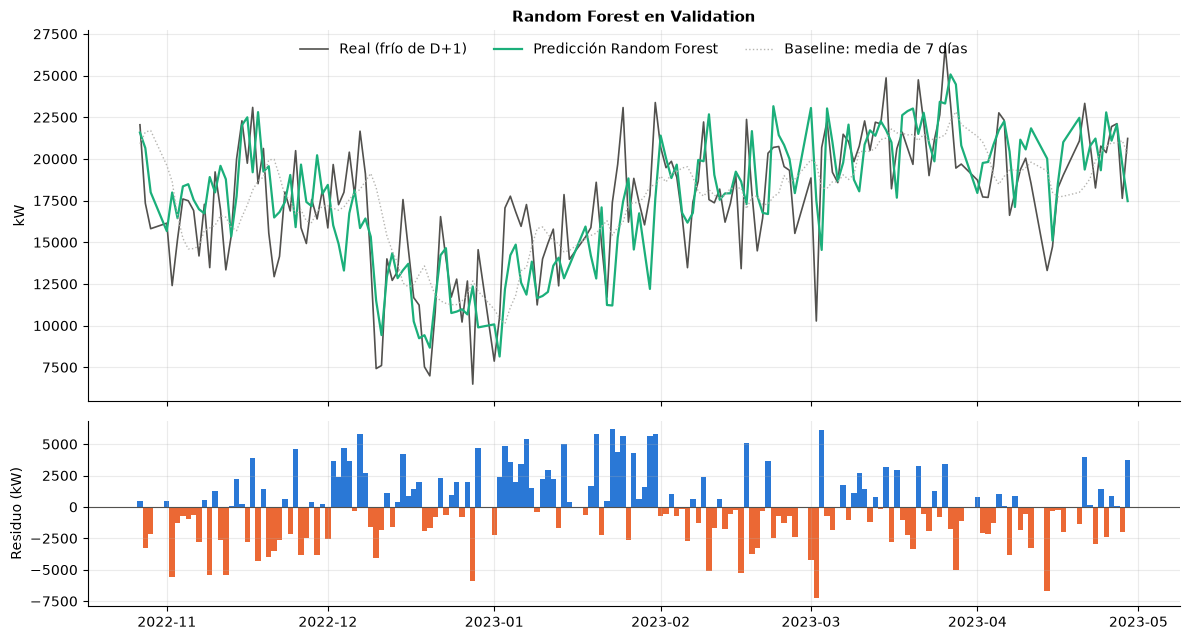

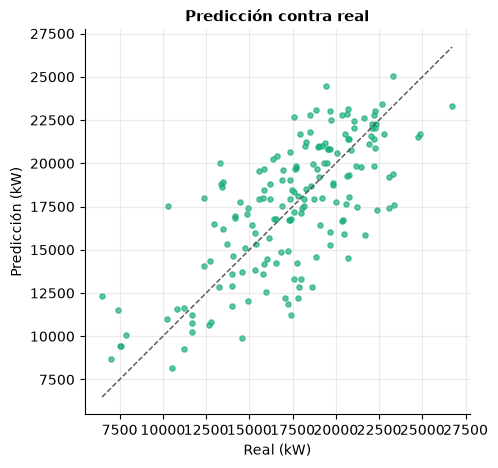

,días,MAE modelo,MAE media 7 días,sesgo (pred − real)
DIA,,,,
2022-10,3,1986.0,3766.0,1673.0
2022-11,30,2366.0,2538.0,1305.0
2022-12,29,2357.0,2910.0,-728.0
2023-01,29,3020.0,2581.0,-2345.0
2023-02,26,1886.0,2002.0,857.0
2023-03,29,2240.0,2018.0,316.0
2023-04,25,1840.0,2114.0,804.0


In [12]:
modelo_ganador = ganador["modelo"]
pred = predicciones[modelo_ganador]
residuo = y_val - pred

fig, axes = plt.subplots(2, 1, figsize=(12, 6.5), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
axes[0].plot(y_val.index, y_val, color="#52514e", lw=1.2, label="Real (frío de D+1)")
axes[0].plot(pred.index, pred, color=COLORES[modelo_ganador], lw=1.6, label=f"Predicción {modelo_ganador}")
axes[0].plot(X_val.index, X_val["frio_media_7"], color="#b5b4b0", lw=1, ls=":", label="Baseline: media de 7 días")
axes[0].set_ylabel("kW")
axes[0].set_title(f"{modelo_ganador} en Validation")
axes[0].legend(frameon=False, ncol=3, loc="upper center")
axes[1].bar(residuo.index, residuo, color=np.where(residuo >= 0, "#2a78d6", "#eb6834"), width=1)
axes[1].axhline(0, color="#52514e", lw=0.8)
axes[1].set_ylabel("Residuo (kW)")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(y_val, pred, s=14, color=COLORES[modelo_ganador], alpha=0.7)
extremos = [min(y_val.min(), pred.min()), max(y_val.max(), pred.max())]
ax.plot(extremos, extremos, color="#52514e", lw=1, ls="--")
ax.set_xlabel("Real (kW)")
ax.set_ylabel("Predicción (kW)")
ax.set_title("Predicción contra real")
ax.set_aspect("equal")
plt.show()

por_mes = pd.DataFrame({
    "días": residuo.groupby(residuo.index.to_period("M")).size(),
    "MAE modelo": residuo.abs().groupby(residuo.index.to_period("M")).mean(),
    "MAE media 7 días": (y_val - X_val["frio_media_7"]).abs().groupby(residuo.index.to_period("M")).mean(),
    "sesgo (pred − real)": (-residuo).groupby(residuo.index.to_period("M")).mean(),
})
display(por_mes.round(0))

**Lectura:**

* El modelo sigue el nivel y la tendencia del frío, pero suaviza: no anticipa las caídas de un día ni los picos aislados.
* Mejora a la media de 7 días en 5 de los 7 meses. Queda peor en enero (3.020 contra 2.581 kW) y en marzo (2.240 contra 2.018 kW).
* En enero subestima 2.345 kW en promedio: el invierno 2022-23 consumió más que los anteriores (15.585 kW de media en enero de 2023, contra 12.848 en enero de 2022). En noviembre sobreestima 1.305 kW.

## 7. Importancia de variables

Se usa **importancia por permutación en Validation**: cuánto empeora el MAE del modelo ganador si se desordena una variable y se rompe su relación con `y`. Sirve para cualquier modelo y mide la importancia en el período que se pronostica, no en el que se aprendió. Con variables muy correlacionadas (por ejemplo, varias ventanas del frío) la importancia se reparte: desordenar una no cambia mucho porque las otras la sustituyen. Por eso también se permuta **cada familia entera** a la vez: mide cuánto aporta el grupo aunque sus columnas sean redundantes entre sí.

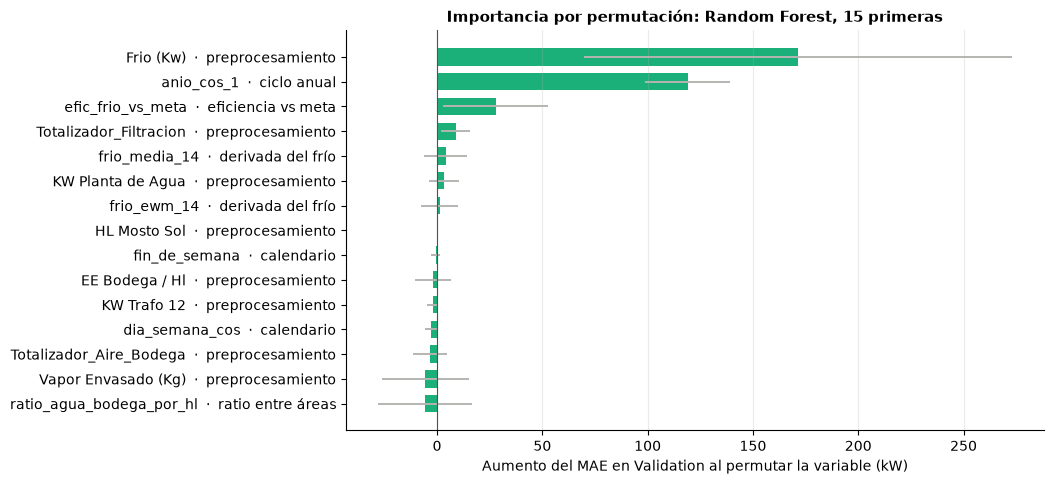

Permutación agrupada por familia (Validation):


,columnas,aumento del MAE (kW),desvío
grupo,,,
frío de D,1,192.3,78.3
ciclo anual,1,170.4,84.7
eficiencia vs meta,1,19.7,21.5
ratio entre áreas,1,13.5,20.8
otras del preprocesamiento,9,7.1,34.0
calendario,2,-1.1,3.8
interacción,1,-43.3,15.7
metas (preprocesamiento),1,-52.2,41.0
derivada del frío,6,-64.5,50.5


In [13]:
estimador, columnas = ajustados[modelo_ganador]
perm = permutation_importance(estimador, X_val[columnas], y_val, scoring="neg_mean_absolute_error",
                              n_repeats=10, random_state=tm.SEMILLA, n_jobs=-1)
importancia = pd.DataFrame({"aumento del MAE (kW)": perm.importances_mean, "desvío": perm.importances_std,
                            "familia": [pp.familia_de(c) for c in columnas]}, index=columnas)
importancia = importancia.sort_values("aumento del MAE (kW)", ascending=False)

top = importancia.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 5.2))
ax.barh([f"{corto(c)}  ·  {f}" for c, f in zip(top.index, top["familia"])], top["aumento del MAE (kW)"],
        xerr=top["desvío"], color=COLORES[modelo_ganador], height=0.7, ecolor="#b5b4b0")
ax.axvline(0, color="#52514e", lw=0.8)
ax.set_xlabel("Aumento del MAE en Validation al permutar la variable (kW)")
ax.set_title(f"Importancia por permutación: {modelo_ganador}, 15 primeras")
ax.grid(axis="y", alpha=0)
plt.show()
# Permutación agrupada: se desordenan juntas todas las columnas de una familia (con la misma
# permutación de filas). Mide cuánto aporta la familia entera aunque sus columnas sean redundantes.
def grupo(c):
    if c == pp.COL_FRIO:
        return "frío de D"
    if c.startswith("Meta "):
        return "metas (preprocesamiento)"
    familia = pp.familia_de(c)
    return "otras del preprocesamiento" if familia == "preprocesamiento" else familia

grupos = {}
for c in columnas:
    grupos.setdefault(grupo(c), []).append(c)
rng = np.random.default_rng(tm.SEMILLA)
mae_base = mean_absolute_error(y_val, estimador.predict(X_val[columnas]))
filas = []
for nombre, cols in grupos.items():
    aumentos = []
    for _ in range(10):
        X_perm = X_val[columnas].copy()
        X_perm[cols] = X_perm[cols].to_numpy()[rng.permutation(len(X_perm))]
        aumentos.append(mean_absolute_error(y_val, estimador.predict(X_perm)) - mae_base)
    filas.append({"grupo": nombre, "columnas": len(cols), "aumento del MAE (kW)": np.mean(aumentos),
                  "desvío": np.std(aumentos)})
print("Permutación agrupada por familia (Validation):")
display(pd.DataFrame(filas).set_index("grupo").sort_values("aumento del MAE (kW)", ascending=False).round(1))

**Lectura:**

* **Por grupo, lo que más aporta es el frío de hoy (192 kW) y el ciclo anual (170 kW).** La eficiencia contra la meta y el ratio de agua de bodega suman poco (20 y 14 kW, con desvíos del mismo orden).
* **Las ventanas del frío (6 columnas), la meta incluida (`Meta ET Cocina`) y la interacción tienen importancia negativa:** desordenarlas baja el MAE de Validation. Son redundantes con el frío de hoy, o aprendieron relaciones de Train que en Validation no se repiten.
* No se quitan por este resultado: hacerlo sería elegir variables mirando Validation, el mismo error que volvió optimista el MAE de Validation de la versión 1.

## 8. Registro de experimentos

Cada trial (`tipo = optuna`, partición `train_cv`), cada candidato en Validation (`candidato`) y los baselines quedaron en `results/experiment_logs.csv`, con el mismo formato que la versión anterior: hiperparámetros, MAE, RMSE, R², fechas evaluadas y la marca de tiempo de la corrida.

In [14]:
log = pd.read_csv(tm.RUTA_LOG)
esta_corrida = log[log["corrida_utc"] == corrida]
print(f"Filas agregadas al log en esta corrida: {len(esta_corrida)} (total del log: {len(log)})")
display(esta_corrida.groupby(["tipo", "particion", "modelo"]).size().rename("filas").to_frame())

Filas agregadas al log en esta corrida: 327 (total del log: 2912)


filas
tipo      particion  modelo                      
baseline  validation Media móvil de 7 días      1
                     Persistencia               1
candidato validation Lasso                      1
                     LightGBM                   1
                     Random Forest              1
                     Ridge                      1
                     XGBoost                    1
optuna    train_cv   Lasso                     40
                     LightGBM                 100
                     Random Forest             60
                     Ridge                     40
                     XGBoost                   80

## 9. Evaluación final en Test, registro y versión

La elección quedó fijada en la sección 5 con el criterio establecido de antemano: menor MAE en Validation. Recién entonces:

1. El ganador se **reentrena con Train y Validation** y se evalúa **una sola vez** en Test, junto a los dos baselines sobre las mismas filas. Es la tabla que pide la primera pregunta de las conclusiones de la consigna.
2. `registrar_modelo` guarda `models/modelo_<VERSION>.pkl` (hoy `modelo_v2.0.0.pkl`) con el modelo y todo lo que la predicción necesita: el pipeline del preprocesamiento y las variables creadas, ambos ajustados con Train, y la calibración de la limpieza horaria. Registra la versión en `models/model_registry.json` con sus hiperparámetros, métricas de Validation y de Test, ruta, SHA-256 y commit de Git.
3. Exporta `data/processed/dataset_final.csv` (sin escalar), `data_lineage.json` con el recorrido de los datos, y agrega sus SHA-256 a `data/checksums.json`.

**Test se evalúa una sola vez por versión.** Si `tm.VERSION` ya está en `models/model_registry.json`, la celda no vuelve a leer Test: comprueba que la configuración ganadora sea la registrada y muestra el resultado guardado en `results/experiment_logs.csv` por la corrida que la evaluó. Para registrar otra configuración hay que cambiar `VERSION` en `src/train_model.py`.

**Regenerar el .pkl sin volver a leer Test.** `python -m src.train_model --regenerar-registro` reajusta con Train y Validation la configuración registrada desde el código del commit actual, comprueba que predice exactamente lo mismo que el .pkl registrado (verificado con su SHA-256) y actualiza el .pkl, su SHA-256 y el commit del registro. Las métricas de Test siguen siendo las de la evaluación única.


In [15]:
registro_previo = json.loads((raiz / "models" / "model_registry.json").read_text(encoding="utf-8")).get(tm.VERSION)
conjunto, params = tm.mejor_configuracion(estudios[modelo_ganador])
columnas_finales = tm.columnas_de(subconjuntos[conjunto], params.get("objetivo_y", "nivel"))
X_te = tm.particion_test(d["historial"], d["candidatas"])[0]  # solo las predictoras, para la sección 9.1
print(f"X_train: {X_tr.shape} | X_val: {X_val.shape} | X_test: {X_te.shape} "
      f"({X_te.index.min().date()} a {X_te.index.max().date()})")

tabla_test = None
if registro_previo is not None:
    if registro_previo["modelo"] != modelo_ganador or registro_previo["columnas"] != columnas_finales:
        raise ValueError(f"La configuración ganadora no es la registrada como {tm.VERSION}: "
                         "cambiar VERSION en src/train_model.py para registrar una versión nueva.")
    print(f"{tm.VERSION} ya está registrada: Test no se vuelve a evaluar. Resultado guardado:")
    # La evaluación única quedó en el log, con la marca de la corrida que figura en el registro.
    log_test = pd.read_csv(tm.RUTA_LOG)
    log_test = log_test[(log_test["corrida_utc"] == registro_previo["corrida_utc"])
                        & (log_test["particion"] == "test")].reset_index(drop=True)
    tabla_test = log_test[["modelo", "mae", "rmse", "r2"]].copy()
    tabla_test.loc[log_test["tipo"] == "final", "modelo"] += " (final)"
    registro = registro_previo
elif EVALUAR_TEST:
    X_te, y_te = tm.particion_test(d["historial"], d["candidatas"])
    tabla_test, modelo_final, pred_test = tm.evaluar_en_test(
        modelo_ganador, conjunto, params, columnas_finales, X_tr, y_tr, X_val, y_val, X_te, y_te, corrida, cfg)
    registro = tm.registrar_modelo(ganador, conjunto, params, columnas_finales, modelo_final, tabla_test,
                                    d, X_te, corrida)
else:
    print("Test no evaluado (EVALUAR_TEST = False). La elección se hizo solo con Train y Validation.")

if tabla_test is not None:
    mejor_baseline_test = tabla_test.iloc[:2]["mae"].min()
    display(tabla_test.assign(**{"vs mejor baseline": (1 - tabla_test["mae"] / mejor_baseline_test)
                                 .map("{:+.1%}".format)}).round(1))
    # El SHA-256 y el commit del .pkl están en models/model_registry.json.
    display(pd.Series({k: registro[k] for k in ("path", "modelo", "conjunto",
                                                "n_train_validation", "metricas_validation", "metricas_test")},
                      name=tm.VERSION).to_frame())

X_train: (786, 360) | X_val: (171, 360) | X_test: (171, 360) (2023-04-30 a 2023-10-24)
v2.0.0 ya está registrada: Test no se vuelve a evaluar. Resultado guardado:


,modelo,mae,rmse,r2,vs mejor baseline
0,Persistencia,3367.8,4412.4,0.4,-11.7%
1,Media móvil de 7 días,3013.8,3889.5,0.5,+0.0%
2,Random Forest (final),2836.7,3698.8,0.6,+5.9%


,v2.0.0
path,models/modelo_v2.0.0.pkl
modelo,Random Forest
conjunto,forward
n_train_validation,957
metricas_validation,"{'mae': 2297.595901, 'rmse': 2859.564602, 'r2': 0.433551}"
metricas_test,"{'mae': 2836.720499, 'rmse': 3698.834713, 'r2': 0.576318}"


### 9.1 La predicción reproduce el modelo registrado

`src/predict.py` carga la versión del registro y pronostica un Excel nuevo reutilizando el preprocesamiento y las variables creadas guardados en el bundle. Como prueba, se le pasa solo `Totalizadores Planta 2022_2023.xlsx`, sin historial previo, y se comparan sus pronósticos con los del modelo registrado sobre las predictoras de los días de Test. Deberían coincidir, porque la limpieza, el preprocesamiento y las variables son los mismos. La comparación no usa el `y` de Test.

In [16]:
if tabla_test is not None:
    from src.predict import load_model, predict_consumption

    bundle = load_model(tm.VERSION)
    pred_modelo = pd.Series(bundle["modelo"].predict(X_te[bundle["columnas"]]), index=X_te.index)
    excel = raiz / "data" / "raw" / "Totalizadores Planta 2022_2023.xlsx"
    pronostico = predict_consumption(excel, tm.VERSION)
    pronostico = pronostico.set_index(pd.to_datetime(pronostico["fecha"]))["prediccion_frio_kw"]
    comunes = pred_modelo.index.intersection(pronostico.index)
    diferencia = (pronostico.loc[comunes] - pred_modelo.loc[comunes]).abs()
    print(f"Días pronosticados por predict.py: {len(pronostico)} ({pronostico.index.min().date()} a "
          f"{pronostico.index.max().date()})")
    print(f"Días de Test en común: {len(comunes)} de {len(pred_modelo)} | diferencia máxima: "
          f"{diferencia.max():.6f} kW | media: {diferencia.mean():.6f} kW")

AVISO: faltan filas de estas fechas en 'Totalizadores Planta 2022_2023.xlsx': 2022-08-29, 2022-08-30, 2022-08-31, 2022-10-31, 2022-12-31, 2023-03-31, 2023-05-31, 2023-08-30, 2023-08-31.


AVISO: se omitió 2023-01-17. El día tiene 16 lecturas válidas en Frio (Kw) (< 24 requeridas)
AVISO: se omitió 2023-02-28. Frio (Kw) a las 23:59 es NaN o fuera de rango físico (valor=nan)
AVISO: se omitió 2023-04-13. Día incompleto (20 hs): carece del registro de cierre a las 23:59
AVISO: se omitió 2023-04-19. Día incompleto (17 hs): carece del registro de cierre a las 23:59
AVISO: se omitió 2023-07-01. El día tiene 23 lecturas válidas en Frio (Kw) (< 24 requeridas)
AVISO: se omitió 2023-10-26. Día incompleto (8 hs): carece del registro de cierre a las 23:59
AVISO: 'Totalizadores Planta 2022_2023.xlsx' no trae 11 columnas del entrenamiento que el modelo no usa; se completan con la imputación aprendida en Train.


Días pronosticados por predict.py: 468 (2022-07-01 a 2023-10-25)
Días de Test en común: 171 de 171 | diferencia máxima: 0.000000 kW | media: 0.000000 kW


AVISO: hay 0 cierres válidos en los 28 días previos al primer pronóstico (2022-07-01). Las primeras ventanas pueden estar incompletas.
AVISO: 6 días sin historia suficiente para todas las ventanas (desde 2022-07-01); se completan con las medianas de Train.


## 10. Conclusiones

**Qué muestran los resultados:**

* **Ganador: Random Forest** con las 23 variables de forward (200 árboles, profundidad 11). En Validation tiene 2.298 kW de MAE: 4,2 % mejor que la media de 7 días y 15,7 % mejor que la persistencia.
* **Test, evaluado una sola vez** con el modelo reentrenado con Train y Validation: 2.837 kW, contra 3.014 kW de la media de 7 días (5,9 % mejor) y 3.368 kW de la persistencia (15,8 %). La mejora no llega al 10 % que menciona la consigna, y el margen frente al límite de aprobación (3.000 kW) es de 5 %.
* **La predicción reproduce el modelo registrado:** `predict.py`, con solo el Excel 2022_2023, da exactamente los mismos pronósticos que el modelo final en los 171 días de Test.
* **Excluir los componentes del frío ordenó los resultados:** sesgos chicos, error interno correlacionado con el de Validation y los cinco modelos cerca entre sí (2.298 a 2.455 kW).
* **Frente a la versión 1:** el modelo `v1.0.0` (Ridge con 10 variables) tuvo 2.127 kW en Validation, 171 kW menos que este ganador. Con el criterio de reemplazo del informe (una mejora de al menos un error estándar entre bloques, unos 150 kW), v2 no justifica reemplazar a v1 por precisión. El 2.127 de v1 es optimista, porque esa versión se eligió mirando Validation varias veces.
* **Dos mejoras probadas y no adoptadas** (secciones 3.1 y 5.2, y la 1.5 de la selección): el filtro de redundancia empeora en Validation; aprender el cambio mejora la validación interna pero no Validation. La segunda queda como decisión abierta y se activa con una línea (`ConfigModelado.objetivos`). El detalle lo calcula `comparar_variantes()` de `src/auxiliar_functions.py`.
* **La búsqueda es reproducible:** 320 trials en unos 3 minutos, con semilla fija.

**Versión que se entrega:** `v2.0.0`, la más alta del registro, que es la que usa `predict.py` por defecto. Aunque no mejora a v1 en Validation, se elige por el proceso: la EDA y todas las decisiones estadísticas se ajustan solo con Train, y Validation se miró una sola vez para elegir. El MAE de v1 en Validation es optimista por haberse elegido mirándolo varias veces. El código de v1 queda en el tag `v1.0.0` y sus notebooks, como registro, en `notebooks/v1/`.

**Trazabilidad:** el .pkl se regenera desde el commit del código con `--regenerar-registro` (mismas predicciones, sin leer Test) y ese commit queda en el registro y etiquetado `v2.0.0`.

**Pendiente:** pesos por antigüedad en el reentrenamiento final, elegidos con una evaluación mes a mes sobre Validation.